# Forecasting Kazakhstan’s Total Monthly Electricity Generation

**Research question:** Does SARIMA improve three-month forecasts over the same-month-last-year baseline?

Source: [Ember](https://ember-energy.org/data/monthly-electricity-data/). Snapshot downloaded 18 November 2026.

A source audit found January 2018 differed from [Samruk’s original report](https://samruk-energy.kz/images/analitcs/2018_1.docx). The analysis preserves the source values and explicitly documents exclusions. No official course rubric was supplied.

## Environment and reproducibility

The analysis uses a frozen Ember snapshot. Install the pinned requirements before rerunning. Run all cells in order. Figures and CSV results are regenerated locally.

In [1]:
"""Kazakhstan electricity project. Run this file or the matching notebook.
Data are a frozen Ember snapshot downloaded on 2026-11-18.
"""
from pathlib import Path
import sys, os, json, warnings, hashlib, platform
BASE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
if not (BASE / 'data').exists():
    BASE = BASE / 'outputs'
os.environ.setdefault('MPLCONFIGDIR', str(BASE / '.cache' / 'matplotlib'))
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import statsmodels
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy.stats import norm
for name in ['results', 'figures']:
    (BASE / name).mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'serif', 'font.size':11, 'axes.spines.top':False,
                     'axes.spines.right':False, 'figure.dpi':140, 'savefig.dpi':180})
BLUE, ORANGE, GREY = '#194c76', '#b34d22', '#707070'
def savefig(name):
    plt.tight_layout()
    image_path = BASE / 'figures' / (name + '.png')
    plt.savefig(image_path, bbox_inches='tight')
    plt.close()
    if 'get_ipython' in globals():
        from IPython.display import display, Image
        display(Image(filename=str(image_path)))
print('Versions:', platform.python_version(), 'numpy', np.__version__, 'pandas', pd.__version__, 'statsmodels', statsmodels.__version__)

Versions: 3.12.14 numpy 2.5.5 pandas 3.1.1 statsmodels 0.15.0


## 1. Data audit and chronological split

The snapshot has 102 months. The main study uses 84 months from 2019–2025. A source discrepancy motivates excluding 2018. Initial training: 2019–2023; validation: 2024; test: 2025. No values are interpolated or corrected. The partial 2026 year is outside the main experiment.

In [2]:
# 1. Audit the unchanged national series. No interpolation or manual correction.
raw_path = BASE / 'data' / 'kazakhstan_generation_snapshot.csv'
raw = pd.read_csv(raw_path, parse_dates=['Date'])
assert raw['Date'].is_unique
assert raw['Generation_TWh'].notna().all()
full = raw.set_index('Date')['Generation_TWh'].sort_index().asfreq('MS')
assert full.notna().all() and (full > 0).all() and len(full) == 102
assert full.index.min() == pd.Timestamp('2018-01-01')
assert full.index.max() == pd.Timestamp('2026-06-01')
repeats = full[full.eq(full.shift())]
audit = {'snapshot_downloaded':'2026-11-18', 'analysis_date':'2026-11-22',
         'source_url':'https://files.ember-energy.org/public-downloads/generation/outputs/release_generation_monthly_global.csv',
         'filter':{'Area':'Kazakhstan','Electricity source':'Total generation','target':'Generation (TWh)'},
         'snapshot_sha256':hashlib.sha256(raw_path.read_bytes()).hexdigest(),
         'n_full':len(full), 'start':str(full.index[0].date()), 'end':str(full.index[-1].date()),
         'missing_targets':int(full.isna().sum()), 'duplicate_dates':0,
         'adjacent_repeats':{str(d.date()):float(v) for d,v in repeats.items()},
         'source_check':{'samruk_january_2018_twh':10.3573,'ember_january_2018_twh':float(full.iloc[0]),
                         'samruk_Q1_2018_twh':29.3392,'ember_Q1_2018_twh':float(full.iloc[:3].sum()),
                         'interpretation':'Quarterly averaging is plausible, not established for all months.'}}
# Chosen on data-quality/calendar grounds before computing model errors.
y = full.loc['2019-01-01':'2025-12-01']
train = y.loc[:'2023-12-01']
validation = y.loc['2024-01-01':'2024-12-01']
test = y.loc['2025-01-01':'2025-12-01']
assert (len(y),len(train),len(validation),len(test)) == (84,60,12,12)
print('Full snapshot:', len(full), 'months; main study:',len(y),'months')
print('Training / validation / test:',len(train),len(validation),len(test))
print('Adjacent exact repeats:',audit['adjacent_repeats'])
print('January 2018 source discrepancy: 9.780 versus 10.3573 TWh')
(BASE/'results'/'data_audit.json').write_text(json.dumps(audit,indent=2))

Full snapshot: 102 months; main study: 84 months
Training / validation / test: 60 12 12
Adjacent exact repeats: {'2018-02-01': 9.78, '2018-03-01': 9.78, '2018-05-01': 8.591, '2018-07-01': 8.087, '2018-08-01': 8.087, '2018-09-01': 8.087, '2020-12-01': 10.454, '2022-12-01': 10.569}
January 2018 source discrepancy: 9.780 versus 10.3573 TWh


## 2. Training-set exploration

Only the initial training sample informs seasonal plots and stationarity checks. ADF tests a unit-root null; KPSS tests a level-stationarity null. Their finite-sample conclusions need not agree. KPSS p-values at table limits are bounds.

                       Series  n  ADF_stat  ADF_p  KPSS_stat  KPSS_p_table_bound
                       Levels 60   -2.2581 0.1858     0.1830              0.1000
          Seasonal difference 48   -4.1437 0.0008     0.3580              0.0953
Seasonal and first difference 47   -8.0512 0.0000     0.2658              0.1000


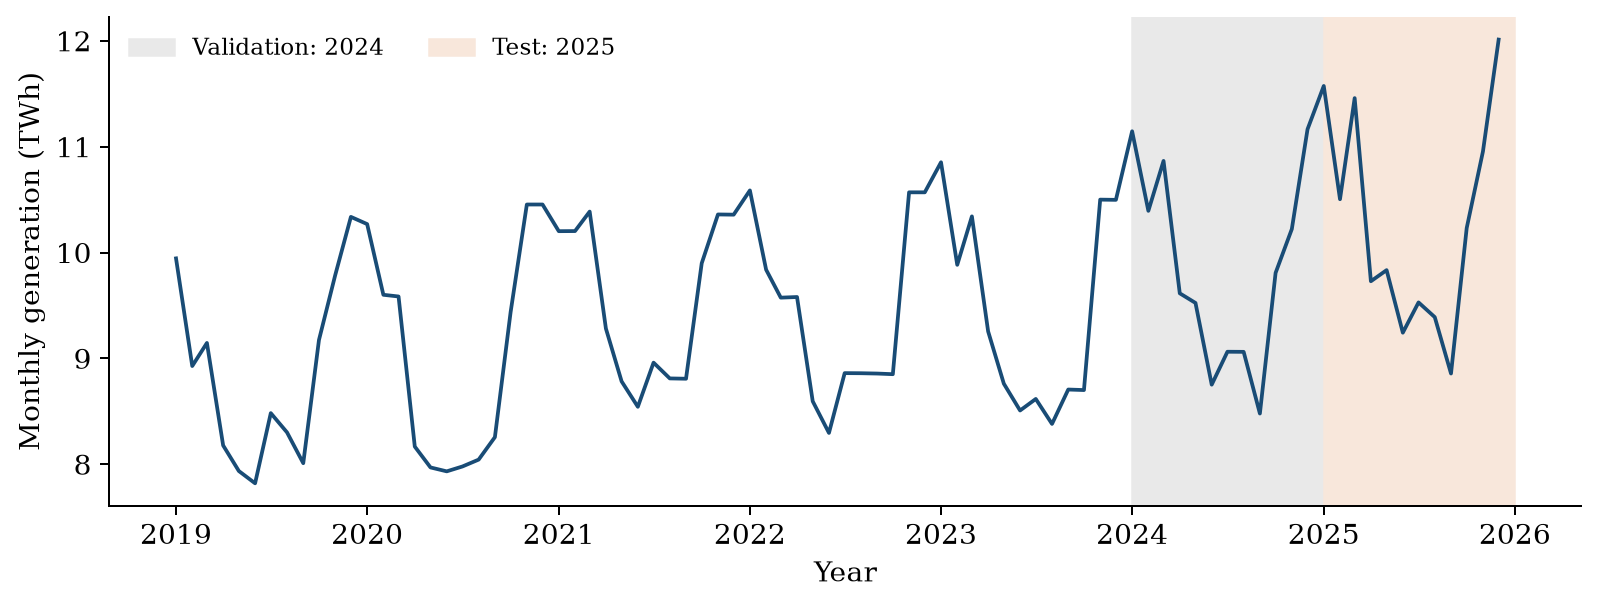

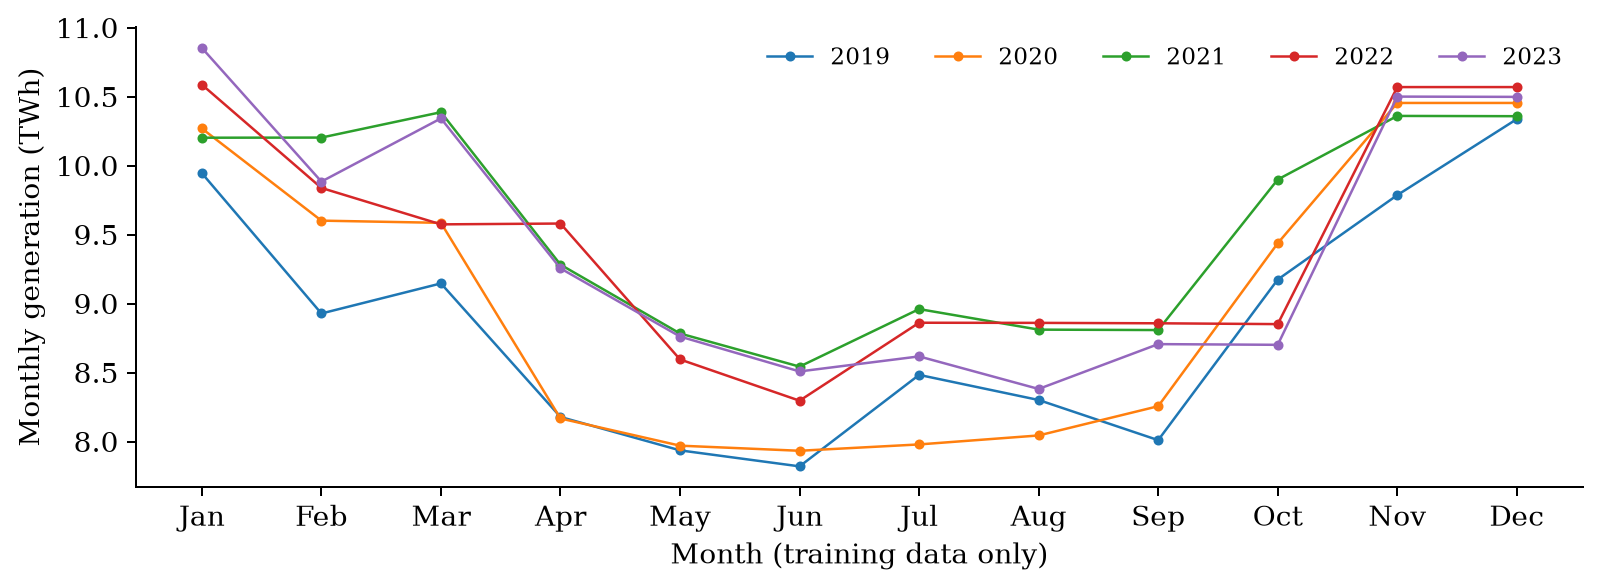

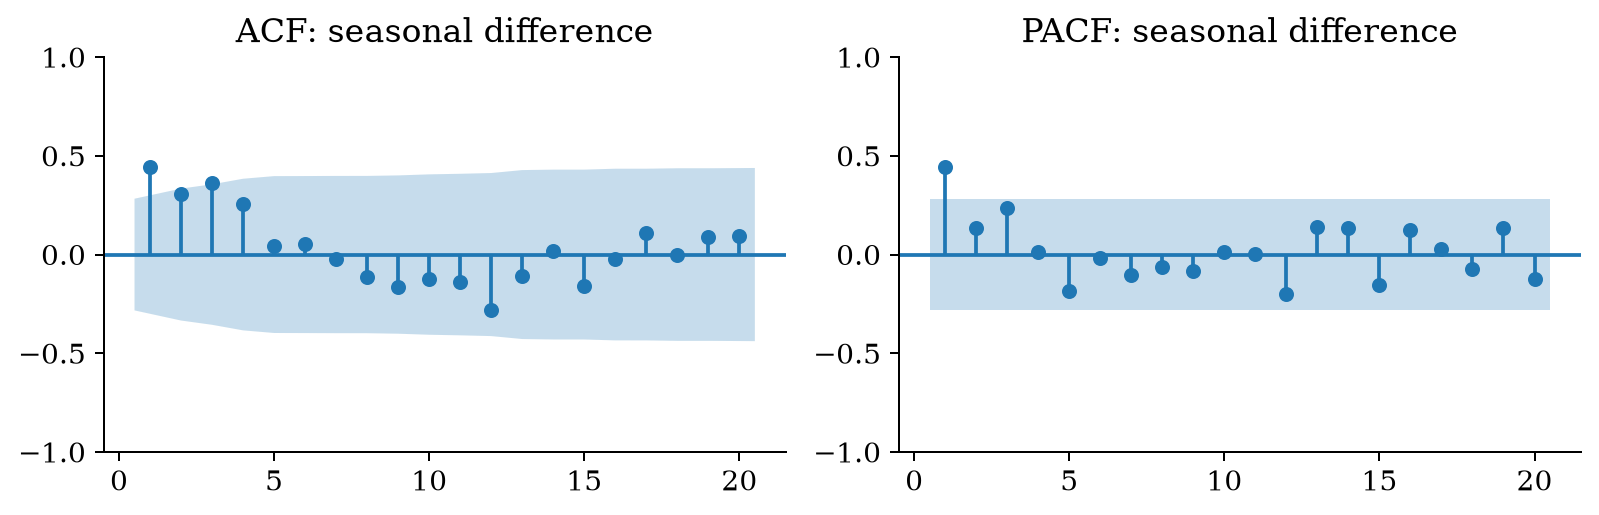

In [3]:
# 2. Exploration and stationarity use the INITIAL TRAINING SET only.
fig, ax = plt.subplots(figsize=(9,3.5))
ax.plot(y.index,y.values,color=BLUE,lw=1.5)
ax.axvspan(pd.Timestamp('2024-01-01'),pd.Timestamp('2024-12-31'),color='#e9e9e9',label='Validation: 2024')
ax.axvspan(pd.Timestamp('2025-01-01'),pd.Timestamp('2025-12-31'),color='#f8e7db',label='Test: 2025')
ax.set(ylabel='Monthly generation (TWh)',xlabel='Year')
ax.legend(frameon=False,fontsize=9,loc='upper left',ncol=2)
savefig('01_history')
fig, ax = plt.subplots(figsize=(9,3.4))
for year,g in train.groupby(train.index.year):
    ax.plot(g.index.month,g.values,marker='o',ms=3,lw=1,label=str(year))
ax.set(xticks=range(1,13),xticklabels=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'],
       ylabel='Monthly generation (TWh)',xlabel='Month (training data only)')
ax.legend(frameon=False,ncol=5,fontsize=9)
savefig('02_seasonality')
stationarity=[]
for name,z in [('Levels',train),('Seasonal difference',train.diff(12).dropna()),
               ('Seasonal and first difference',train.diff(12).diff().dropna())]:
    adf = adfuller(z,regression='c',autolag='AIC',maxlag=8,result_object=False)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        kp=kpss(z,regression='c',nlags='auto')
    stationarity.append({'Series':name,'n':len(z),'ADF_stat':adf[0],'ADF_p':adf[1],
                         'KPSS_stat':kp[0],'KPSS_p_table_bound':kp[1]})
stationarity=pd.DataFrame(stationarity)
stationarity.to_csv(BASE/'results'/'stationarity.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(9,3))
plot_acf(train.diff(12).dropna(),lags=20,zero=False,ax=axs[0],title='ACF: seasonal difference')
plot_pacf(train.diff(12).dropna(),lags=20,zero=False,method='ywm',ax=axs[1],title='PACF: seasonal difference')
savefig('03_acf_pacf')
print(stationarity.round(4).to_string(index=False))

## 3. Prespecified candidates and validation

Compare eight low-order SARIMA candidates on four three-month blocks in 2024. Choose the smallest validation MAE, with AICc only as a tie-breaker. A constant in a seasonally differenced model allows average annual growth. The 2025 test data do not enter selection.

In [4]:
# 3. Eight prespecified low-order candidates. The test year is never used to select.
CANDIDATES = [
    ((1,0,0),(1,1,0,12),'c'), ((1,0,0),(0,1,1,12),'c'),
    ((0,0,1),(0,1,1,12),'c'), ((1,0,1),(0,1,1,12),'c'),
    ((0,1,1),(0,1,1,12),'n'), ((1,1,0),(0,1,1,12),'n'),
    ((0,1,1),(1,1,0,12),'n'), ((1,1,0),(1,1,0,12),'n')]
def label(spec):
    order,season,trend=spec
    return f'SARIMA{order}{season[:3]}[12]' + (' + constant' if trend=='c' else '')
fit_log=[]
def fit_model(hist,spec):
    order,season,trend=spec
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        fit=SARIMAX(hist,order=order,seasonal_order=season,trend=trend,
                    enforce_stationarity=True,enforce_invertibility=True).fit(disp=False,maxiter=500)
    ok=bool(fit.mle_retvals.get('converged',False)) and np.isfinite(fit.params).all()
    fit_log.append({'last_training_month':str(hist.index[-1].date()),'model':label(spec),
                    'converged':bool(ok),'warnings':[str(w.message) for w in caught]})
    if not ok:
        raise RuntimeError('Fit did not converge: '+label(spec))
    return fit
def errors(actual,pred):
    e=np.asarray(actual)-np.asarray(pred)
    return {'MAE':float(np.mean(np.abs(e))),'RMSE':float(np.sqrt(np.mean(e**2))),
            'Bias_actual_minus_forecast':float(np.mean(e))}
def backtest(series,start,end,spec=None):
    dates=pd.date_range(start,end,freq='MS'); records=[]
    assert len(dates)%3==0
    for origin in dates[::3]:
        hist=series.loc[series.index<origin]
        assert hist.index.max()<origin
        future=pd.date_range(origin,periods=3,freq='MS')
        if spec is None:
            pred=np.array([hist.loc[d-pd.DateOffset(years=1)] for d in future])
            scale=float(np.sqrt(np.mean(hist.diff(12).dropna()**2)))
            lo80,hi80=pred-norm.ppf(.9)*scale,pred+norm.ppf(.9)*scale
            lo95,hi95=pred-norm.ppf(.975)*scale,pred+norm.ppf(.975)*scale
        else:
            fit=fit_model(hist,spec)
            fc=fit.get_forecast(steps=3)
            pred=np.asarray(fc.predicted_mean)
            ci80=np.asarray(fc.conf_int(alpha=.2)); ci95=np.asarray(fc.conf_int(alpha=.05))
            lo80,hi80=ci80[:,0],ci80[:,1]; lo95,hi95=ci95[:,0],ci95[:,1]
        for i,d in enumerate(future):
            records.append({'Date':d,'origin':hist.index[-1],'horizon':i+1,
                'actual':float(series.loc[d]),'forecast':float(pred[i]),'lower80':float(lo80[i]),
                'upper80':float(hi80[i]),'lower95':float(lo95[i]),'upper95':float(hi95[i])})
    return pd.DataFrame(records)
validation_rows=[]
for i,spec in enumerate(CANDIDATES):
    first_fit=fit_model(train,spec)
    bt=backtest(y,'2024-01-01','2024-12-01',spec)
    validation_rows.append({'candidate':i,'Model':label(spec),'initial_AICc':float(first_fit.aicc),
                            **errors(bt.actual,bt.forecast)})
    print('Validated',label(spec),flush=True)
validation_scores=pd.DataFrame(validation_rows).sort_values(['MAE','initial_AICc'])
selected=CANDIDATES[int(validation_scores.iloc[0]['candidate'])]
validation_scores.to_csv(BASE/'results'/'validation_scores.csv',index=False)
vb=backtest(y,'2024-01-01','2024-12-01')
print('Selected on validation MAE:',label(selected))
print(validation_scores.round(4).to_string(index=False))
print('Validation baseline:',errors(vb.actual,vb.forecast))

Validated SARIMA(1, 0, 0)(1, 1, 0)[12] + constant
Validated SARIMA(1, 0, 0)(0, 1, 1)[12] + constant
Validated SARIMA(0, 0, 1)(0, 1, 1)[12] + constant
Validated SARIMA(1, 0, 1)(0, 1, 1)[12] + constant
Validated SARIMA(0, 1, 1)(0, 1, 1)[12]
Validated SARIMA(1, 1, 0)(0, 1, 1)[12]
Validated SARIMA(0, 1, 1)(1, 1, 0)[12]
Validated SARIMA(1, 1, 0)(1, 1, 0)[12]
Selected on validation MAE: SARIMA(1, 0, 0)(0, 1, 1)[12] + constant
 candidate                                   Model  initial_AICc    MAE   RMSE  Bias_actual_minus_forecast
         1 SARIMA(1, 0, 0)(0, 1, 1)[12] + constant       50.7014 0.3537 0.4127                      0.1557
         2 SARIMA(0, 0, 1)(0, 1, 1)[12] + constant       53.7377 0.3576 0.4168                      0.1597
         3 SARIMA(1, 0, 1)(0, 1, 1)[12] + constant       50.0787 0.3777 0.4345                      0.1426
         0 SARIMA(1, 0, 0)(1, 1, 0)[12] + constant       52.7814 0.3998 0.4722                      0.2120
         5            SARIMA(1, 1, 0)(0, 

## 4. Held-out evaluation

Freeze the selected order. Refit parameters at December 2024, March, June and September 2025. Each model predicts the same next three months without updating within a block. Observed earlier blocks may enter later fits. MAE and RMSE are in TWh. Report horizon-specific scores with only four observations per horizon.

         Model    MAE   RMSE  Bias_actual_minus_forecast  Coverage80  Coverage95
Seasonal naive 0.4352 0.4830                      0.4352      0.8333      1.0000
        SARIMA 0.3434 0.4175                      0.2698      0.7500      0.8333
         Model  horizon  n    MAE   RMSE  Bias_actual_minus_forecast
        SARIMA        1  4 0.3183 0.3389                      0.1939
        SARIMA        2  4 0.1913 0.2249                      0.1913
        SARIMA        3  4 0.5204 0.5979                      0.4241
Seasonal naive        1  4 0.3580 0.3851                      0.3580
Seasonal naive        2  4 0.3703 0.4339                      0.3703
Seasonal naive        3  4 0.5773 0.6027                      0.5773


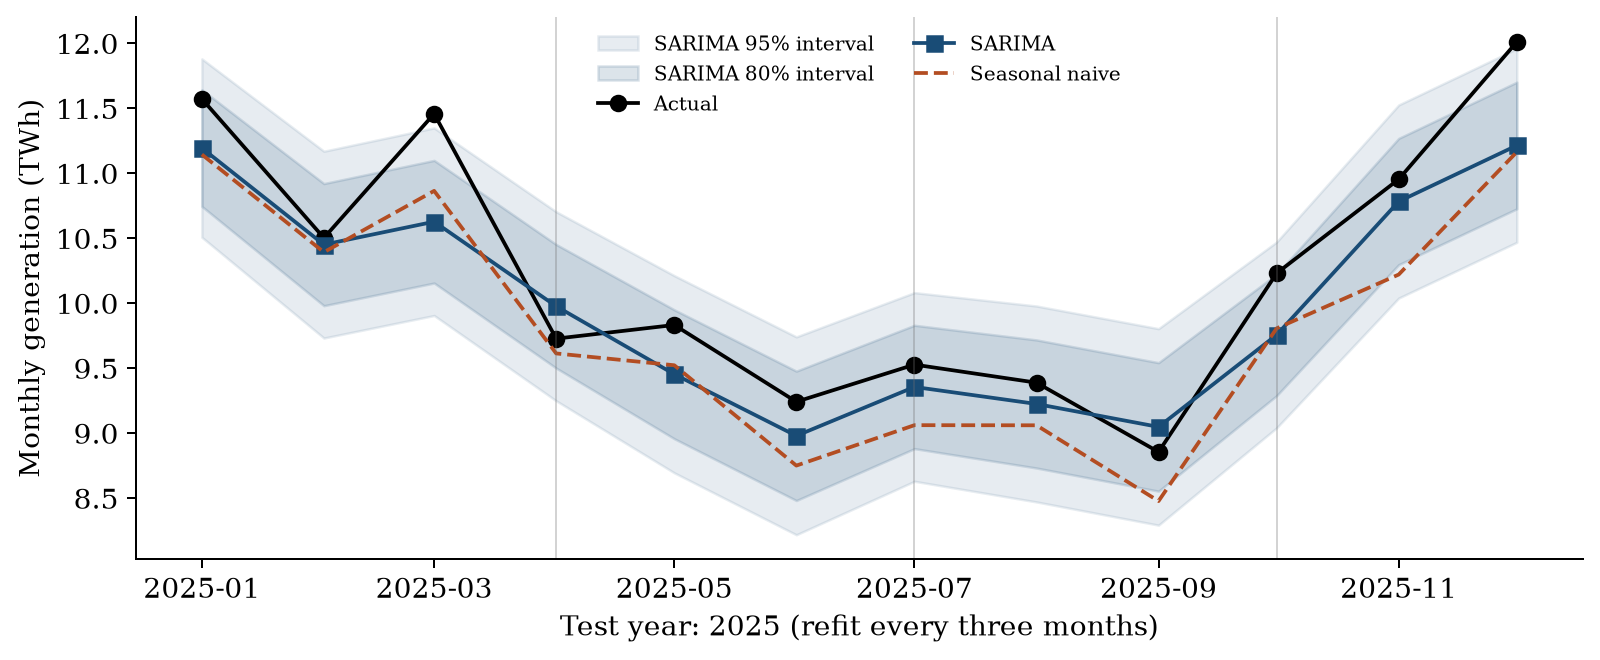

In [5]:
# 4. Frozen model specification, four quarterly forecast origins, same horizons.
baseline=backtest(y,'2025-01-01','2025-12-01')
sarima=backtest(y,'2025-01-01','2025-12-01',selected)
assert baseline.Date.equals(sarima.Date) and baseline.origin.equals(sarima.origin)
all_predictions=pd.concat([baseline.assign(Model='Seasonal naive'),sarima.assign(Model='SARIMA')])
all_predictions.to_csv(BASE/'results'/'test_predictions.csv',index=False)
test_rows=[]
for name,g in all_predictions.groupby('Model',sort=False):
    test_rows.append({'Model':name,**errors(g.actual,g.forecast),
        'Coverage80':float(((g.actual>=g.lower80)&(g.actual<=g.upper80)).mean()),
        'Coverage95':float(((g.actual>=g.lower95)&(g.actual<=g.upper95)).mean())})
test_scores=pd.DataFrame(test_rows)
test_scores.to_csv(BASE/'results'/'test_scores.csv',index=False)
horizon_rows=[]
for (model,h),g in all_predictions.groupby(['Model','horizon']):
    horizon_rows.append({'Model':model,'horizon':h,'n':len(g),**errors(g.actual,g.forecast)})
horizon_scores=pd.DataFrame(horizon_rows)
horizon_scores.to_csv(BASE/'results'/'horizon_scores.csv',index=False)
print(test_scores.round(4).to_string(index=False))
print(horizon_scores.round(4).to_string(index=False))
fig,ax=plt.subplots(figsize=(9,3.8))
ax.fill_between(sarima.Date,sarima.lower95,sarima.upper95,color=BLUE,alpha=.10,label='SARIMA 95% interval')
ax.fill_between(sarima.Date,sarima.lower80,sarima.upper80,color=BLUE,alpha=.15,label='SARIMA 80% interval')
ax.plot(sarima.Date,sarima.actual,color='black',marker='o',label='Actual')
ax.plot(sarima.Date,sarima.forecast,color=BLUE,marker='s',label='SARIMA')
ax.plot(baseline.Date,baseline.forecast,color=ORANGE,ls='--',label='Seasonal naive')
for d in ['2025-04-01','2025-07-01','2025-10-01']:
    ax.axvline(pd.Timestamp(d),color=GREY,alpha=.3,lw=.8)
ax.set(ylabel='Monthly generation (TWh)',xlabel='Test year: 2025 (refit every three months)')
ax.legend(frameon=False,fontsize=8,ncol=2)
savefig('04_test_forecasts')

## 5. Diagnostics

Use the fit through December 2024. Remove 13 initial residuals to reduce initialization effects. Check residual ACF and parameter-adjusted Ljung–Box statistics at lags 12 and 24. Failure to reject does not establish independence or prove the model correct.

Ljung-Box tests (parameter-adjusted):
     lb_stat  lb_pvalue
12   8.0752     0.6215
24  18.8879     0.6522
     term  estimate  std_error  p_value
intercept    0.1214     0.0313   0.0001
    ar.L1    0.3138     0.1409   0.0260
 ma.S.L12   -0.8640     0.3788   0.0226
   sigma2    0.1162     0.0328   0.0004


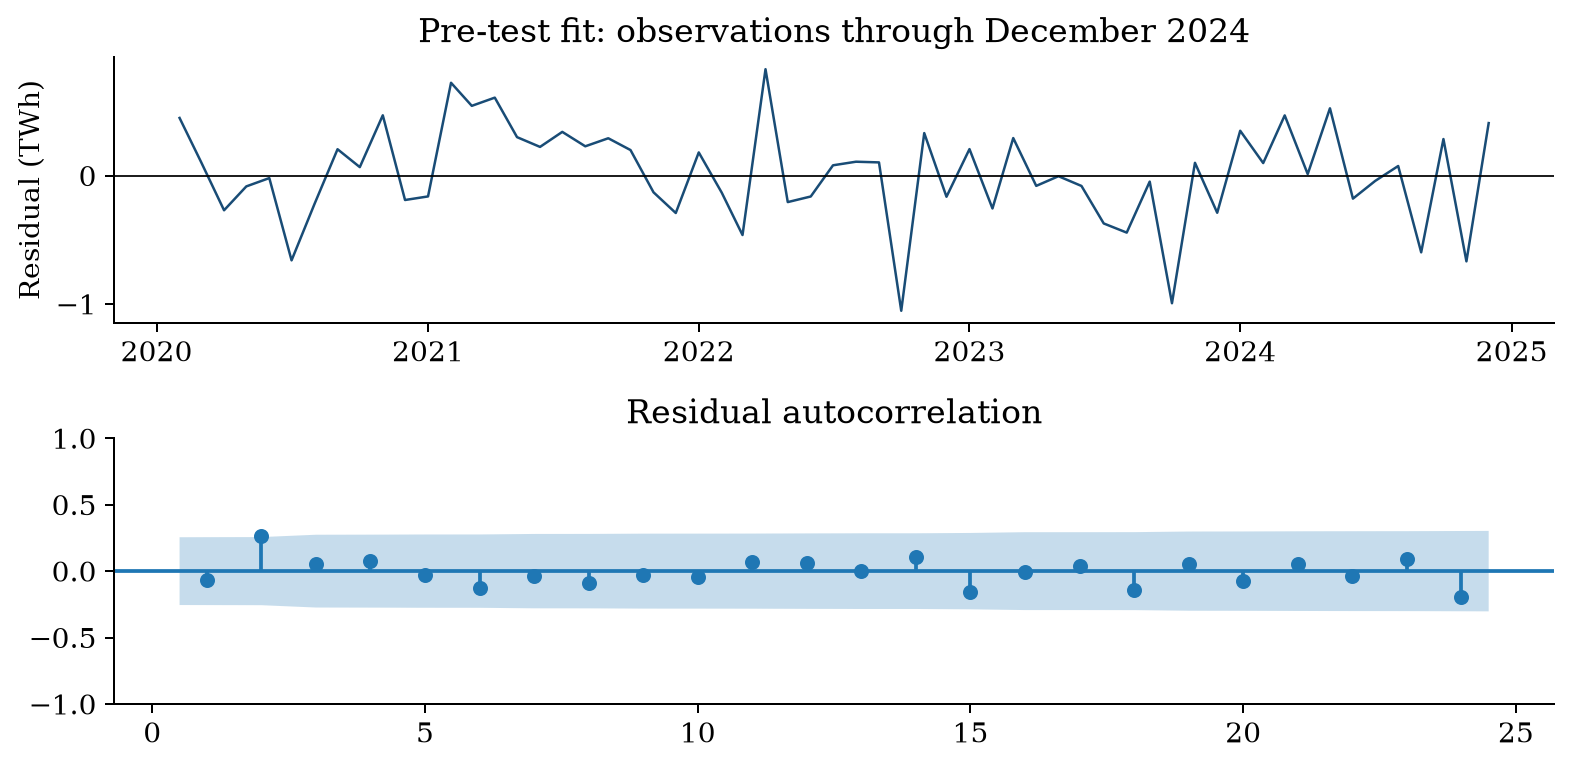

In [6]:
# 5. Diagnostics on the pre-test fit, never used to retune after test scoring.
pretest=y.loc[:'2024-12-01']
diagnostic_fit=fit_model(pretest,selected)
burn=max(int(diagnostic_fit.loglikelihood_burn),13)
residuals=diagnostic_fit.resid.iloc[burn:]
model_df=selected[0][0]+selected[0][2]+selected[1][0]+selected[1][2]
ljung=acorr_ljungbox(residuals,lags=[12,24],model_df=model_df,return_df=True)
ljung.to_csv(BASE/'results'/'ljung_box.csv',index_label='lag')
coefficients=pd.DataFrame({'term':diagnostic_fit.param_names,'estimate':diagnostic_fit.params.values,
                           'std_error':diagnostic_fit.bse.values,'p_value':diagnostic_fit.pvalues.values})
coefficients.to_csv(BASE/'results'/'coefficients.csv',index=False)
fig,axs=plt.subplots(2,1,figsize=(9,4.4))
axs[0].plot(residuals.index,residuals.values,color=BLUE,lw=1)
axs[0].axhline(0,color='black',lw=.7)
axs[0].set(ylabel='Residual (TWh)',title='Pre-test fit: observations through December 2024')
plot_acf(residuals,lags=24,zero=False,ax=axs[1],title='Residual autocorrelation')
savefig('05_residuals')
print('Ljung-Box tests (parameter-adjusted):\n',ljung.round(4))
print(coefficients.round(4).to_string(index=False))

## 6. Sensitivity and dated illustration

Keep the selected specification unchanged when adding 2018 back. The January–March 2026 forecast is an illustration using information through December 2025. It is not a live forecast from November 2026, and its subsequent actual values are not used for model selection.

In [7]:
# 6. Sensitivity: same selected specification, add 2018 back without retuning.
sensitivity=backtest(full.loc[:'2025-12-01'],'2025-01-01','2025-12-01',selected)
sensitivity.to_csv(BASE/'results'/'sensitivity_predictions.csv',index=False)
sensitivity_metrics=errors(sensitivity.actual,sensitivity.forecast)
# Illustration beyond the main study endpoint, not a current November forecast.
illustration_fit=fit_model(y,selected)
illustration_fc=illustration_fit.get_forecast(steps=3)
ci=np.asarray(illustration_fc.conf_int(alpha=.05))
illustration=pd.DataFrame({'Date':pd.date_range('2026-01-01',periods=3,freq='MS'),
    'forecast':np.asarray(illustration_fc.predicted_mean),'lower95':ci[:,0],'upper95':ci[:,1]})
illustration.to_csv(BASE/'results'/'dated_forecast_illustration.csv',index=False)
base_mae=float(test_scores.loc[test_scores.Model=='Seasonal naive','MAE'].iloc[0])
model_mae=float(test_scores.loc[test_scores.Model=='SARIMA','MAE'].iloc[0])
summary={'selected_order':list(selected[0]),'selected_seasonal_order':list(selected[1]),'trend':selected[2],
    'selected_label':label(selected),'main_n':len(y),'train_n':len(train),'validation_n':len(validation),
    'test_n':len(test),'baseline_validation':errors(vb.actual,vb.forecast),
    'validation':validation_scores.to_dict('records'),'test':test_scores.to_dict('records'),
    'mae_improvement_percent':100*(base_mae-model_mae)/base_mae,
    'sensitivity_include_2018':sensitivity_metrics,'ljung_box':ljung.reset_index().to_dict('records'),
    'stationarity':stationarity.to_dict('records'),
    'coefficients':coefficients.to_dict('records'),'residual_mean':float(residuals.mean()),
    'residual_sd':float(residuals.std()),'burn_removed':burn,
    'initial_training_seasonal_acf12':float(acf(train,nlags=12)[12]),
    'all_fits_converged':all(r['converged'] for r in fit_log),
    'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
                'scipy':__import__('scipy').__version__,'statsmodels':statsmodels.__version__,
                'matplotlib':matplotlib.__version__}}
(BASE/'results'/'summary.json').write_text(json.dumps(summary,indent=2))
(BASE/'results'/'fit_log.json').write_text(json.dumps(fit_log,indent=2))
# Chart-ready values also used for editable presentation charts.
chart_data={'history_dates':[d.strftime('%Y-%m') for d in y.index], 'history':y.tolist(),
    'seasonal_months':['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'],
    'seasonal':{str(k):g.tolist() for k,g in train.groupby(train.index.year)},
    'test_dates':[d.strftime('%b') for d in sarima.Date],
    'actual':sarima.actual.tolist(),'sarima':sarima.forecast.tolist(),'baseline':baseline.forecast.tolist(),
    'lower95':sarima.lower95.tolist(),'upper95':sarima.upper95.tolist(),
    'residual_dates':[d.strftime('%Y-%m') for d in residuals.index], 'residuals':residuals.tolist(),
    'residual_acf':acf(residuals,nlags=24,fft=False).tolist()[1:]}
(BASE/'results'/'chart_data.json').write_text(json.dumps(chart_data,indent=2))
print('MAE reduction versus seasonal naive: %.1f%%' % summary['mae_improvement_percent'])
print('Including 2018, same SARIMA:',sensitivity_metrics)
print('All fits converged:',summary['all_fits_converged'])
print('Dated illustration, information through December 2025:\n',illustration.to_string(index=False,float_format=lambda v:f'{v:.3f}'))
print('No claim of a live forecast for November 2026 is made.')

MAE reduction versus seasonal naive: 21.1%
Including 2018, same SARIMA: {'MAE': 0.3596161232261486, 'RMSE': 0.44076727703388763, 'Bias_actual_minus_forecast': 0.27440731673002244}
All fits converged: True
Dated illustration, information through December 2025:
       Date  forecast  lower95  upper95
2026-01-01    11.860   11.130   12.590
2026-02-01    10.812   10.052   11.572
2026-03-01    11.367   10.605   12.129
No claim of a live forecast for November 2026 is made.


## Interpretation

The selected model is **SARIMA(1, 0, 0)(0, 1, 1)[12] + constant**. Test MAE falls by **21.1%** against the seasonal naive baseline. This is evidence for this particular small historical test, not proof of permanent superiority.

The 95% SARIMA intervals cover only 10 of 12 test observations. Source construction, remaining repeated values, revisions and the small sample limit interpretation. Including 2018 is a sensitivity analysis, not a second opportunity to select a model.

## References

- Ember. Monthly electricity data and methodology. https://ember-energy.org/data/monthly-electricity-data/
- Samruk-Energy. Electricity market analysis, January and January–March 2018. https://samruk-energy.kz/en/press-center/analytical-review
- Hyndman, R. J. and Athanasopoulos, G. Forecasting: Principles and Practice, 3rd ed., Chapters 5 and 9. https://otexts.com/fpp3/
- statsmodels SARIMAX documentation. https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html
